# CMG SR3 &rarr; thermal energy + water by group, one table per case

Reads every `.sr3` in a folder once and writes **one CSV per case** holding
both quantities on the same time grid:

| end_date | inj_energy_PJ | pro_energy_PJ | inj_water_m3 | pro_water_m3 |
|---|---|---|---|---|
| 2030-01-01 | 0.000000 | 0.000000 | 0.0 | 0.0 |
| 2031-01-01 | 0.112202 | 1.924103 | 5331918.3 | 5560542.7 |
| 2060-01-01 | 2.622613 | 42.266272 | 124627843.4 | 125535311.0 |

Energy is the cumulative enthalpy of each group in PJ &mdash; net extraction is
`pro_energy_PJ - inj_energy_PJ`, computed below for the plots. Water is
cumulative volume in m&sup3;, summed over each group. Rows are 1 January of
each year, linearly interpolated between simulator timesteps.

This replaces `batch_net_energy.py` + `extract_annual_water.py`. The energy
difference reproduces the old `*_net_energy.csv` files to 1e-6 PJ, and the
final water row matches the `.out` group summary to within its
5-significant-figure printing.

**How to use:** set `SR3_FOLDER` in the next cell, then *Run All*.

> **Windows paths:** keep the `r` prefix &mdash; `r"z:\jding\runs"`. Without it
> Python turns `\n`, `\t`, `\260` etc. into control characters and the path
> breaks. Forward slashes (`"z:/jding/runs"`) also work everywhere.

Requires `h5py`, `pandas`, `matplotlib`, and `batch_sr3.py`. If anything is
missing:

```
pip install h5py pandas matplotlib
```

## 1. Settings

In [1]:
# ============================================================
#  EDIT THIS   -- keep the r"" prefix on Windows paths
# ============================================================

SR3_FOLDER = r"sim_gen_000"          # folder holding the .sr3 files
OUTPUT_DIR = r"sim_gen_000\0_energy_water_csv"  # per-case CSVs go here

# ============================================================

ANNUAL_ONLY = True      # True  -> one row per 1 January (interpolated)
                        # False -> every simulator timestep
YEARLY      = False     # True  -> per-year increments instead of running totals
BASIS       = "surface" # "surface" (WATVOLSC, STC) or "reservoir" (WATVOLRC)

CASE_ONLY   = True      # True  -> case1.sr3, case2.sr3, ... only, numeric order
FILE_GLOB   = "*.sr3"   # used when CASE_ONLY is False
RECURSIVE   = False     # also search sub-folders

# Leave as None to classify wells by the WELLOPMO sign (name-independent).
# Set to regexes only if that ever picks wrong, e.g. r"^P" / r"^I".
PROD_PATTERN = None
INJ_PATTERN  = None

WRITE_SUMMARY = True    # also write summary.csv (one row per case)

# Path to batch_sr3.py -- leave as-is if it sits next to this notebook
MODULE_PATH = r"extract_energy_water_from_sr3.py"

## 2. Load the extractor

In [2]:
import importlib.util
import re
from pathlib import Path

import pandas as pd

_mod_path = Path(str(MODULE_PATH).strip().strip('"').strip("'"))
if not _mod_path.is_absolute():
    _mod_path = Path.cwd() / _mod_path

if not _mod_path.exists():
    raise FileNotFoundError(
        f"batch_sr3.py not found at {_mod_path}\n"
        f"Put it next to this notebook, or set MODULE_PATH to its full path."
    )

_spec = importlib.util.spec_from_file_location("batch_sr3", _mod_path)
bsr = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(bsr)

# clean_path strips stray quotes and repairs backslash escapes eaten by Python
folder = bsr.clean_path(SR3_FOLDER, "SR3_FOLDER")
outdir = bsr.clean_path(OUTPUT_DIR, "OUTPUT_DIR")
if not folder.is_absolute():
    folder = Path.cwd() / folder
if not outdir.is_absolute():
    outdir = Path.cwd() / outdir

if not folder.is_dir():
    raise NotADirectoryError(
        f"SR3_FOLDER does not exist:\n    {folder}\n"
        f'Check the drive is mapped and the r"" prefix is present.'
    )

found = list(folder.glob(("**/" if RECURSIVE else "") + FILE_GLOB))

if CASE_ONLY:
    CASE_RE = re.compile(r"^case(\d+)\.sr3$", re.IGNORECASE)
    matched = sorted(((int(m.group(1)), f) for f in found
                      if (m := CASE_RE.match(f.name))), key=lambda t: t[0])
    files = [f for _, f in matched]
    ids = [n for n, _ in matched]
    ignored = sorted(f.name for f in found if not CASE_RE.match(f.name))
    if ignored:
        print(f"ignoring {len(ignored)} non-case file(s): "
              f"{', '.join(ignored[:5])}{' ...' if len(ignored) > 5 else ''}")
    dupes = {n for n in ids if ids.count(n) > 1}
    if dupes:
        print(f"WARNING: case number(s) {sorted(dupes)} appear more than once "
              f"-- files will overwrite each other.")
else:
    files = sorted(found)

prod_re = re.compile(PROD_PATTERN, re.I) if PROD_PATTERN else None
inj_re = re.compile(INJ_PATTERN, re.I) if INJ_PATTERN else None

print(f"{len(files)} file(s) in {folder}")
for f in files[:10]:
    print("  ", f.name)
if len(files) > 10:
    print(f"   ... and {len(files) - 10} more")
print(f"\noutput -> {outdir}")
print("sampling:", "1 January of each year" if ANNUAL_ONLY else "every timestep",
      "|", "per-year increments" if YEARLY else "running totals",
      "|", BASIS, "water")

200 file(s) in z:\jding\project_OMV_geothermal\well_placement_optimization_GA\ga_simulations\sim_gen_000
   case1.sr3
   case2.sr3
   case3.sr3
   case4.sr3
   case5.sr3
   case6.sr3
   case7.sr3
   case8.sr3
   case9.sr3
   case10.sr3
   ... and 190 more

output -> z:\jding\project_OMV_geothermal\well_placement_optimization_GA\ga_simulations\sim_gen_000\0_energy_water_csv
sampling: 1 January of each year | running totals | surface water


## 3. Run the extraction

One CSV per case is written to `OUTPUT_DIR`. Each table is also kept in memory
as `tables[case]` for the checks and plots below.

In [3]:
tables, rows, problems, kinds = {}, [], [], {}

for f in files:
    try:
        df, k, raw_end = bsr.case_table(str(f), basis=BASIS,
                                        annual=ANNUAL_ONLY, yearly=YEARLY,
                                        prod_re=prod_re, inj_re=inj_re)
        suffix = "energy_water_yearly" if YEARLY else "energy_water"
        if BASIS == "reservoir":
            suffix += "_rc"
        dest = bsr.safe_write(df, outdir / f"{f.stem}_{suffix}.csv")

        case = bsr.case_id(f)
        tables[case] = df
        kinds.update(k)
        final = df.sum() if YEARLY else df.iloc[-1]
        row = {"case": case, "end_date": raw_end, "n_rows": len(df),
               "csv": dest.name}
        row.update({c: float(final[c]) for c in df.columns})
        rows.append(row)
        print(f"{f.stem}: {len(df)} rows x {len(df.columns)} cols -> {dest.name}")
    except Exception as exc:
        problems.append((f.name, f"{type(exc).__name__}: {exc}"))
        print(f"{f.stem}: SKIPPED ({type(exc).__name__}: {exc})")

if not rows:
    raise RuntimeError("nothing parsed -- check SR3_FOLDER and the file names")

summary = (pd.DataFrame(rows)
           .sort_values("case", key=lambda s: s.map(lambda v: (isinstance(v, str), v)))
           .reset_index(drop=True))

inj = sorted([w for w, k in kinds.items() if k == "INJ"], key=bsr._natkey)
pro = sorted([w for w, k in kinds.items() if k == "PRO"], key=bsr._natkey)
print(f"\n{len(tables)} case(s) parsed | injectors {inj} | producers {pro}")
print("(the CSVs hold group totals; per-well curves via bsr.read_sr3)")
if problems:
    print(f"{len(problems)} file(s) failed:")
    for name, err in problems:
        print("  x", name, err)

case1: 31 rows x 4 cols -> case1_energy_water.csv
case2: 31 rows x 4 cols -> case2_energy_water.csv
case3: 31 rows x 4 cols -> case3_energy_water.csv
case4: 31 rows x 4 cols -> case4_energy_water.csv
case5: 31 rows x 4 cols -> case5_energy_water.csv
case6: 31 rows x 4 cols -> case6_energy_water.csv
case7: 31 rows x 4 cols -> case7_energy_water.csv
case8: 31 rows x 4 cols -> case8_energy_water.csv
case9: 31 rows x 4 cols -> case9_energy_water.csv
case10: 31 rows x 4 cols -> case10_energy_water.csv
case11: 31 rows x 4 cols -> case11_energy_water.csv
case12: 31 rows x 4 cols -> case12_energy_water.csv
case13: 31 rows x 4 cols -> case13_energy_water.csv
case14: 31 rows x 4 cols -> case14_energy_water.csv
case15: 31 rows x 4 cols -> case15_energy_water.csv
case16: 31 rows x 4 cols -> case16_energy_water.csv
case17: 31 rows x 4 cols -> case17_energy_water.csv
case18: 31 rows x 4 cols -> case18_energy_water.csv
case19: 31 rows x 4 cols -> case19_energy_water.csv
case20: 31 rows x 4 cols -> ca

## 4. Summary file

One row per case. `end_date` is the run's **actual** final date, while the
other columns are the last row of that case's CSV. For a run that stops
mid-year with `ANNUAL_ONLY = True` those refer to different instants, which is
what `n_rows` is there to reveal.

In [4]:
if WRITE_SUMMARY:
    out = summary.drop(columns=["csv"]).copy()
    out["end_date"] = pd.to_datetime(out["end_date"]).dt.strftime("%Y-%m-%d")
    dest = bsr.safe_write(out, outdir / "summary.csv", index=False)
    print(f"wrote {dest}")

summary.drop(columns=["csv"])

wrote z:\jding\project_OMV_geothermal\well_placement_optimization_GA\ga_simulations\sim_gen_000\0_energy_water_csv\summary.csv


,case,end_date,n_rows,inj_energy_PJ,pro_energy_PJ,inj_water_m3,pro_water_m3
0,1,2060-01-01,31,6.915310,109.537529,328618799.2,328569811.4
1,2,2060-01-01,31,5.221606,85.259636,248133215.7,248795148.5
2,3,2060-01-01,31,6.916063,111.547954,328654619.5,328589700.0
3,4,2060-01-01,31,0.515744,8.570162,24508381.8,24840401.3
4,5,2060-01-01,31,6.915337,110.945047,328620103.1,328543986.8
...,...,...,...,...,...,...,...
189,196,2060-01-01,31,1.291632,19.295824,61378989.2,61700993.2
190,197,2060-01-01,31,1.174987,17.730032,55835957.2,56169439.9
191,198,2060-01-01,31,3.662147,54.747997,174026989.7,174672556.1
192,199,2060-01-01,31,6.915806,101.541161,328642403.7,328621493.6


## 5. Sanity checks

With `*GCONP *RECYCLE *WATER 1.0` the injected and produced totals should track
each other closely. A large gap means the injectors hit their BHP ceiling and
the VRI group control throttled the producers to match — that is what
separates a high-throughput realization from a poor one.

In [5]:
chk = summary.set_index("case")[
    ["end_date", "n_rows", "inj_energy_PJ", "pro_energy_PJ",
     "inj_water_m3", "pro_water_m3"]].copy()
chk["net_energy_PJ"] = chk.pro_energy_PJ - chk.inj_energy_PJ
chk["balance_%"] = 100 * (chk.inj_water_m3 - chk.pro_water_m3) / chk.pro_water_m3

expected = pd.to_datetime(chk["end_date"]).mode().iloc[0]
early = chk.index[pd.to_datetime(chk["end_date"]) != expected]
print(f"cases ending before {expected:%Y-%m-%d}:", list(early) or "none")

if not YEARLY:
    bad = [c for c, t in tables.items() if (t.diff().iloc[1:] < -1e-6).any().any()]
    print("non-monotonic cumulative curves:", bad or "none")

chk.style.format({"inj_energy_PJ": "{:,.2f}", "pro_energy_PJ": "{:,.2f}",
                  "net_energy_PJ": "{:,.2f}", "inj_water_m3": "{:,.0f}",
                  "pro_water_m3": "{:,.0f}", "balance_%": "{:+.2f}"})

cases ending before 2060-01-01: [22, 66]
non-monotonic cumulative curves: none


,end_date,n_rows,inj_energy_PJ,pro_energy_PJ,inj_water_m3,pro_water_m3,net_energy_PJ,balance_%
case,,,,,,,,
1,2060-01-01 00:00:00,31,2.62,42.27,"124,627,843","125,535,311",39.64,-0.72
2,2060-01-01 00:00:00,31,3.72,59.89,"176,762,531","177,968,331",56.18,-0.68
3,2060-01-01 00:00:00,31,6.92,103.32,"328,710,559","328,660,624",96.41,+0.02
4,2060-01-01 00:00:00,31,6.92,104.45,"328,710,031","328,672,256",97.54,+0.01
5,2060-01-01 00:00:00,31,6.92,104.48,"328,710,098","328,676,409",97.56,+0.01
6,2060-01-01 00:00:00,31,6.92,105.32,"328,710,021","328,685,097",98.40,+0.01
7,2060-01-01 00:00:00,31,6.45,99.81,"306,429,294","307,063,577",93.36,-0.21
8,2060-01-01 00:00:00,31,5.80,91.49,"275,837,166","276,357,303",85.68,-0.19
9,2060-01-01 00:00:00,31,0.80,13.03,"38,089,810","38,428,431",12.23,-0.88


## 6. Plots

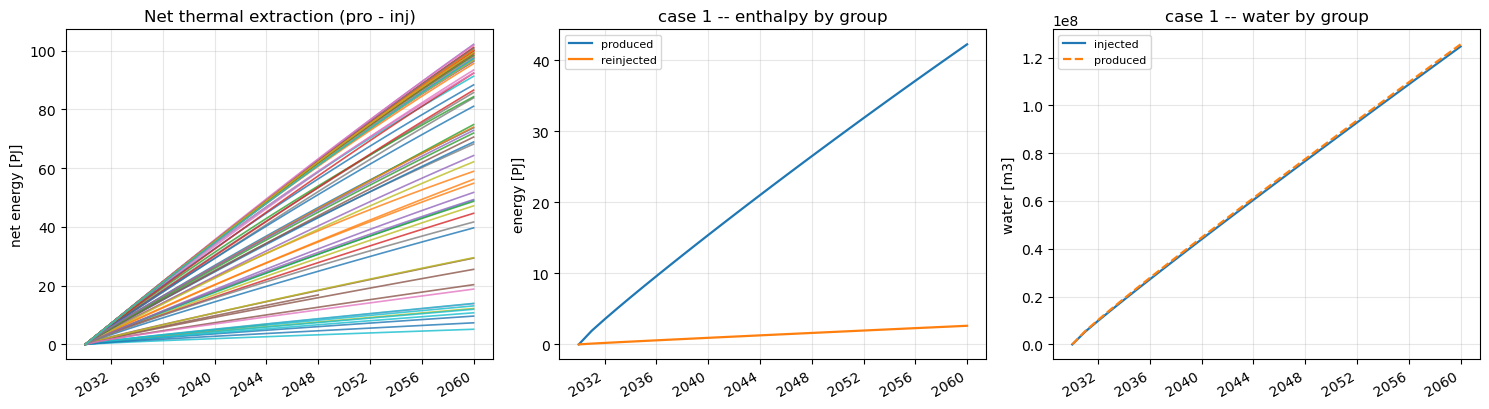

In [6]:
import matplotlib.pyplot as plt

case = summary["case"].iloc[0]          # change to inspect another case
t = tables[case]
x = pd.to_datetime(t.index)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for c, s in tables.items():
    net = s["pro_energy_PJ"] - s["inj_energy_PJ"]
    axes[0].plot(pd.to_datetime(s.index), net, lw=1.2, alpha=.8,
                 label=f"case {c}" if len(tables) <= 10 else None)
axes[0].set(ylabel="net energy [PJ/yr]" if YEARLY else "net energy [PJ]",
            title="Net thermal extraction (pro - inj)")
axes[0].grid(alpha=.3)
if len(tables) <= 10:
    axes[0].legend(fontsize=8)

axes[1].plot(x, t["pro_energy_PJ"], lw=1.6, label="produced")
axes[1].plot(x, t["inj_energy_PJ"], lw=1.6, label="reinjected")
axes[1].set(ylabel="energy [PJ/yr]" if YEARLY else "energy [PJ]",
            title=f"case {case} -- enthalpy by group")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=.3)

axes[2].plot(x, t["inj_water_m3"], lw=1.6, label="injected")
axes[2].plot(x, t["pro_water_m3"], lw=1.6, ls="--", label="produced")
axes[2].set(ylabel="water [m3/yr]" if YEARLY else "water [m3]",
            title=f"case {case} -- water by group")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 7. Optional: check the interpolation

Annual points against the raw simulator timesteps. The markers should sit on
the line — SR3 timesteps land on simulator steps (e.g. 2058-06-27), not on
calendar dates, so every annual row except the first and last is interpolated.

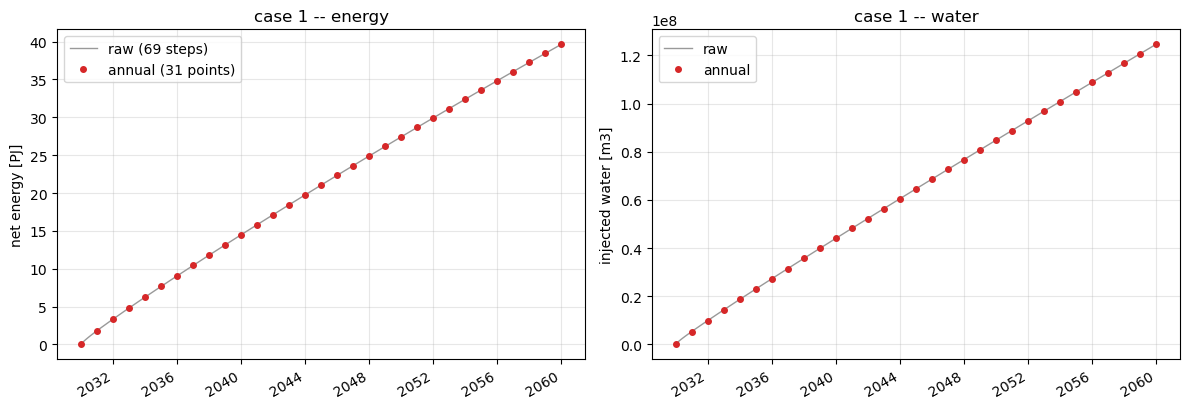

In [7]:
src = [f for f in files if bsr.case_id(f) == case][0]
raw = bsr.read_sr3(str(src), basis=BASIS, prod_re=prod_re, inj_re=inj_re)
ann, _, _ = bsr.case_table(str(src), basis=BASIS, annual=True, yearly=False,
                           prod_re=prod_re, inj_re=inj_re)
ax_x = pd.to_datetime(ann.index)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))

a1.plot(raw["t_energy"], raw["pro_PJ"] - raw["inj_PJ"], "-", lw=1, color="0.6",
        label=f"raw ({len(raw['t_energy'])} steps)")
a1.plot(ax_x, ann["pro_energy_PJ"] - ann["inj_energy_PJ"], "o", ms=4,
        color="C3", label=f"annual ({len(ann)} points)")
a1.set(ylabel="net energy [PJ]", title=f"case {case} -- energy")
a1.legend(); a1.grid(alpha=.3)

a2.plot(raw["t_water"], raw["water"][inj].sum(axis=1), "-", lw=1, color="0.6",
        label="raw")
a2.plot(ax_x, ann["inj_water_m3"], "o", ms=4, color="C3", label="annual")
a2.set(ylabel="injected water [m3]", title=f"case {case} -- water")
a2.legend(); a2.grid(alpha=.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Notes

- The CSVs carry group totals. Per-well curves are still one call away:
  `bsr.read_sr3(path)["water"]` returns a DataFrame with one column per well.
- Water is m³ straight from the SR3, stored as a positive magnitude for
  injectors and producers alike. No unit scaling, unlike the `.out` route where
  CMG prints `Mm3` = 1e3 m³.
- `inj_energy_PJ` and `pro_energy_PJ` share the `*TEMR` enthalpy reference, so
  subtracting them is valid. Both are positive magnitudes.
- Producer/injector classification uses the sign of `WELLOPMO`, not well names,
  and the same call drives both the energy sign convention and the column
  order. `WellTable['Parent']` is unusable: CMG mirrors each group into `-INJ`
  and `-PRO` copies and points injectors at the `-PRO` one, so INJ1 reads
  `INJ-GRP-PRO`.
- `YEARLY = True` is a `.diff()` of everything, so the energy columns become
  annual thermal output and the table has one fewer row.
- The `.out` files cannot replace this: they only print well summary tables at
  the report times (2030/2040/2050/2060 here).
- Equivalent from a terminal, for large ensembles:
  `python batch_sr3.py /path/to/runs -o results --jobs 8 [--yearly]`